In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [9]:
url = "https://huggingface.co/datasets/DElmazi/Student_Performance/resolve/main/student-mat.csv"

df = pd.read_csv(url, sep=";")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [10]:
# Display all column names
print("Dataset Columns:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset Information:")
df.info()

Dataset Columns:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  gua

In [11]:
# Display statistical summary
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [12]:
# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# Check total missing values
print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

Missing Values:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

Total Missing Values:
0

Duplicate Records:
0


In [13]:
# Create a copy of the dataset
df_clean = df.copy()

# Remove duplicate records
df_clean = df_clean.drop_duplicates()

# Handle missing values
df_clean = df_clean.dropna()

# Display final dataset information
print("Data cleaning completed!")

print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)

print("Missing values:", df_clean.isnull().sum().sum())
print("Duplicate records:", df_clean.duplicated().sum())

Data cleaning completed!
Original dataset: (395, 33)
Cleaned dataset: (395, 33)
Missing values: 0
Duplicate records: 0


In [14]:
# Select input features
X = df_clean[['studytime', 'absences', 'G1', 'G2']]

# Select target variable
y = df_clean['G3']

# Display input features
print("Input Features:")
print(X.head())

# Display target variable
print("\nTarget Variable:")
print(y.head())

print("\nInput shape:", X.shape)
print("Target shape:", y.shape)

Input Features:
   studytime  absences  G1  G2
0          2         6   5   6
1          2         4   5   5
2          2        10   7   8
3          3         2  15  14
4          2         4   6  10

Target Variable:
0     6
1     6
2    10
3    15
4    10
Name: G3, dtype: int64

Input shape: (395, 4)
Target shape: (395,)


In [15]:
# Calculate mean, median and standard deviation

print("Mean:")
print(df_clean[['studytime', 'absences', 'G1', 'G2', 'G3']].mean())

print("\nMedian:")
print(df_clean[['studytime', 'absences', 'G1', 'G2', 'G3']].median())

print("\nStandard Deviation:")
print(df_clean[['studytime', 'absences', 'G1', 'G2', 'G3']].std())

Mean:
studytime     2.035443
absences      5.708861
G1           10.908861
G2           10.713924
G3           10.415190
dtype: float64

Median:
studytime     2.0
absences      4.0
G1           11.0
G2           11.0
G3           11.0
dtype: float64

Standard Deviation:
studytime    0.839240
absences     8.003096
G1           3.319195
G2           3.761505
G3           4.581443
dtype: float64


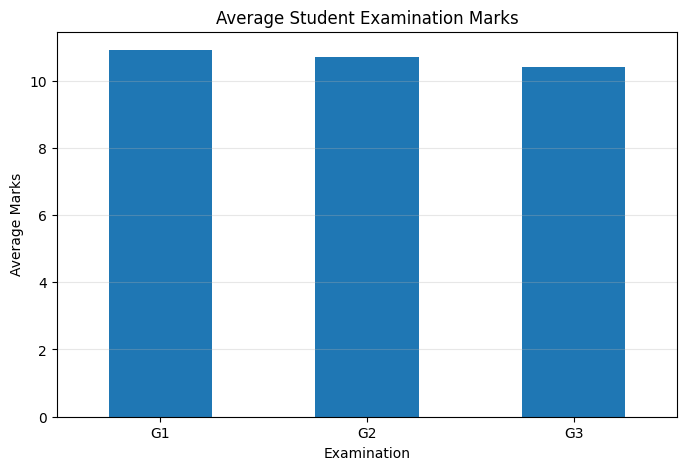

In [16]:
# Calculate average marks
average_marks = df_clean[['G1', 'G2', 'G3']].mean()

# Create bar chart
plt.figure(figsize=(8, 5))

average_marks.plot(kind='bar')

plt.title('Average Student Examination Marks')
plt.xlabel('Examination')
plt.ylabel('Average Marks')

plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

plt.show()

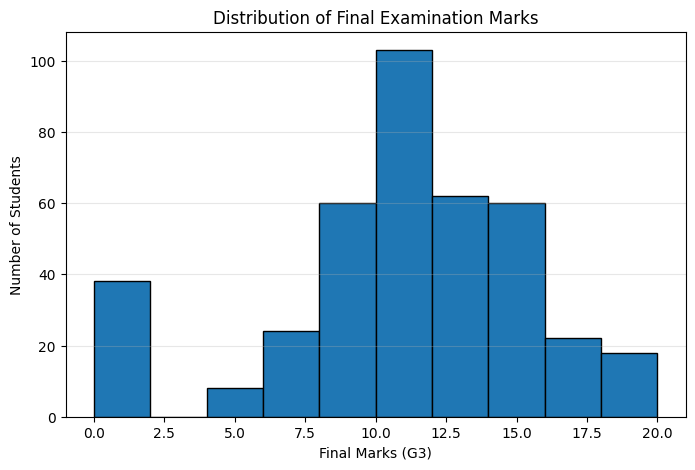

In [17]:
plt.figure(figsize=(8, 5))

plt.hist(df_clean['G3'], bins=10, edgecolor='black')

plt.title('Distribution of Final Examination Marks')
plt.xlabel('Final Marks (G3)')
plt.ylabel('Number of Students')

plt.grid(axis='y', alpha=0.3)

plt.show()

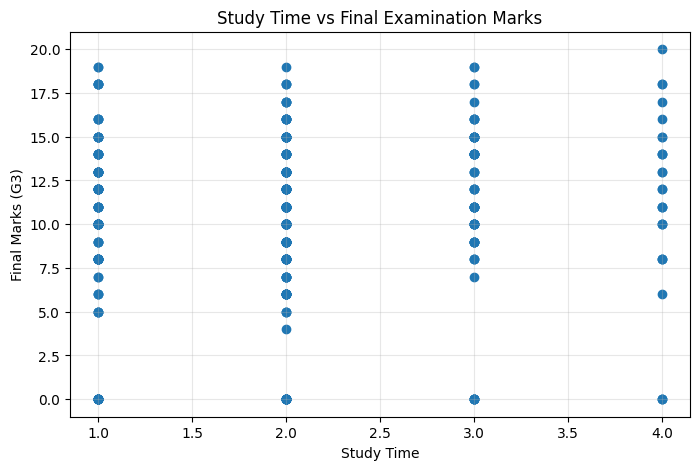

In [18]:
plt.figure(figsize=(8, 5))

plt.scatter(df_clean['studytime'], df_clean['G3'])

plt.title('Study Time vs Final Examination Marks')
plt.xlabel('Study Time')
plt.ylabel('Final Marks (G3)')

plt.grid(alpha=0.3)

plt.show()

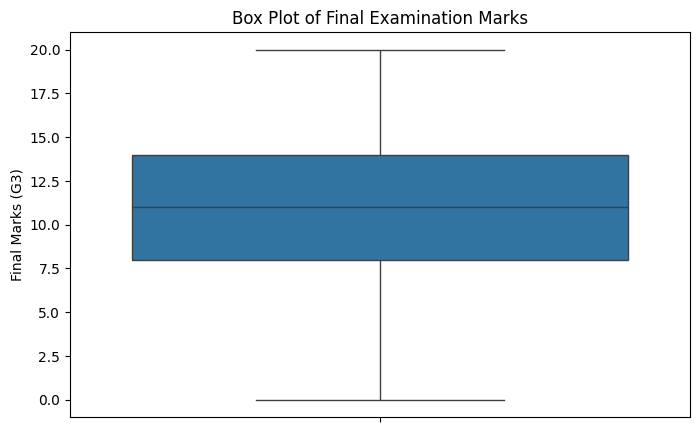

In [19]:
plt.figure(figsize=(8, 5))

sns.boxplot(y=df_clean['G3'])

plt.title('Box Plot of Final Examination Marks')
plt.ylabel('Final Marks (G3)')

plt.show()

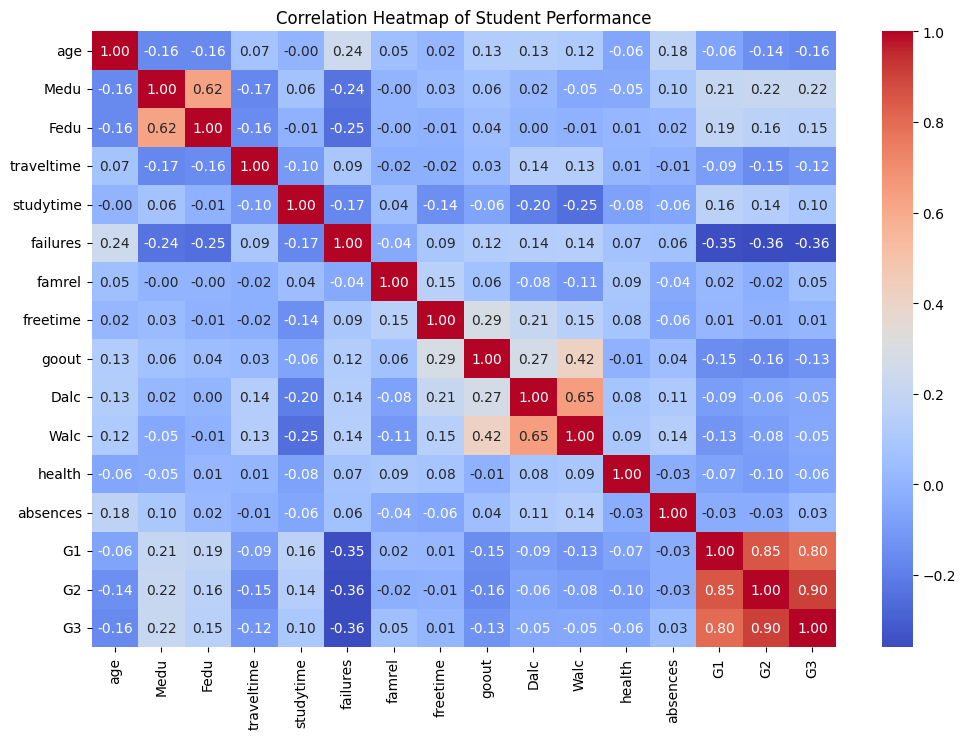

In [20]:
# Calculate correlation between numerical columns
correlation = df_clean.select_dtypes(include=np.number).corr()

# Create heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Student Performance')

plt.show()

In [21]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Display dataset sizes

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Data: (316, 4)
Testing Data: (79, 4)
Training Target: (316,)
Testing Target: (79,)


In [22]:
# Create Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [23]:
# Predict final examination marks
y_pred = model.predict(X_test)

# Display actual and predicted marks
results = pd.DataFrame({
    'Actual Marks': y_test.values,
    'Predicted Marks': y_pred
})

print(results.head(10))

   Actual Marks  Predicted Marks
0            10         7.103031
1            12        12.109229
2             5         3.479554
3            10         8.281773
4             9         8.562709
5            13        12.610665
6            18        18.814522
7             6         6.844699
8             0         6.980266
9            14        12.522121


In [24]:
# Calculate MAE
mae = mean_absolute_error(y_test, y_pred)

# Calculate RMSE
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

# Calculate R2 Score
r2 = r2_score(y_test, y_pred)

# Display results
print("MODEL EVALUATION RESULTS")
print("------------------------")

print("Mean Absolute Error:", mae)
print("Root Mean Squared Error:", rmse)
print("R2 Score:", r2)

MODEL EVALUATION RESULTS
------------------------
Mean Absolute Error: 1.3125749396243547
Root Mean Squared Error: 2.0442542421105148
R2 Score: 0.7961977189442985


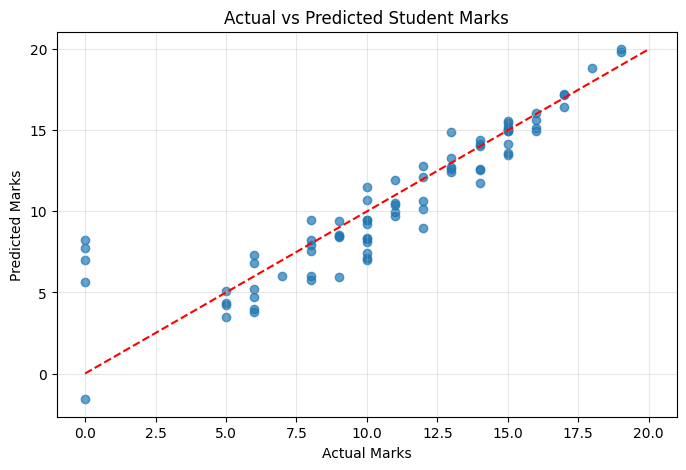

In [25]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.7)

# Perfect prediction reference line
plt.plot([0, 20], [0, 20], 'r--')

plt.title('Actual vs Predicted Student Marks')
plt.xlabel('Actual Marks')
plt.ylabel('Predicted Marks')

plt.grid(alpha=0.3)
plt.show()

In [26]:
from sklearn.model_selection import cross_val_score

# Perform 5-fold cross-validation
cv_scores = cross_val_score(
    LinearRegression(),
    X_train,
    y_train,
    cv=5,
    scoring='r2'
)

# Display results
print("Cross Validation R2 Scores:")
print(cv_scores)

print("\nAverage Cross Validation Score:")
print(cv_scores.mean())

Cross Validation R2 Scores:
[0.82530456 0.85638135 0.86662563 0.80638497 0.7911458 ]

Average Cross Validation Score:
0.8291684628117892


In [27]:
# Enter new student details

new_student = pd.DataFrame({
    'studytime': [3],
    'absences': [4],
    'G1': [12],
    'G2': [14]
})

# Predict final examination marks
prediction = model.predict(new_student)

# Keep prediction within the valid marks range
predicted_marks = np.clip(prediction[0], 0, 20)

print("STUDENT PERFORMANCE PREDICTION")
print("------------------------------")
print("Study Time Category:", 3)
print("Absences:", 4)
print("First Exam Marks:", 12)
print("Second Exam Marks:", 14)

print("\nPredicted Final Marks:", round(predicted_marks, 2))
print("Maximum Marks: 20")

STUDENT PERFORMANCE PREDICTION
------------------------------
Study Time Category: 3
Absences: 4
First Exam Marks: 12
Second Exam Marks: 14

Predicted Final Marks: 13.71
Maximum Marks: 20


In [28]:
import joblib

# Save trained model
joblib.dump(model, 'student_performance_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [29]:
from google.colab import files

files.download('student_performance_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
# Load saved model
loaded_model = joblib.load('student_performance_model.pkl')

# Test prediction
test_prediction = loaded_model.predict(new_student)

print("Loaded Model Prediction:", round(test_prediction[0], 2))

Loaded Model Prediction: 13.71


In [31]:
# Save cleaned dataset as CSV

df_clean.to_csv('student_performance_dataset.csv', index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [32]:
from google.colab import files

files.download('student_performance_dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

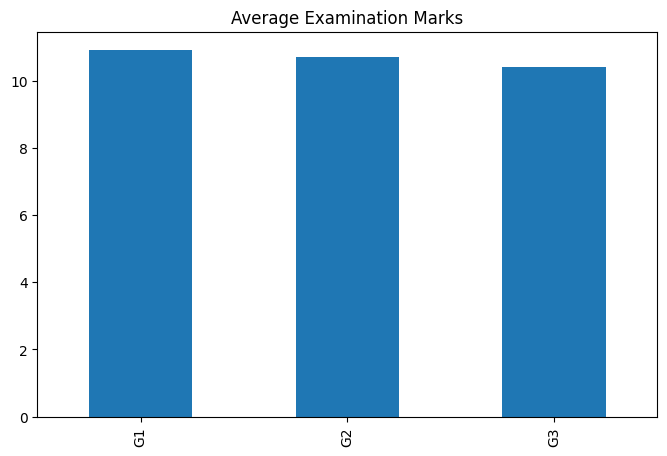

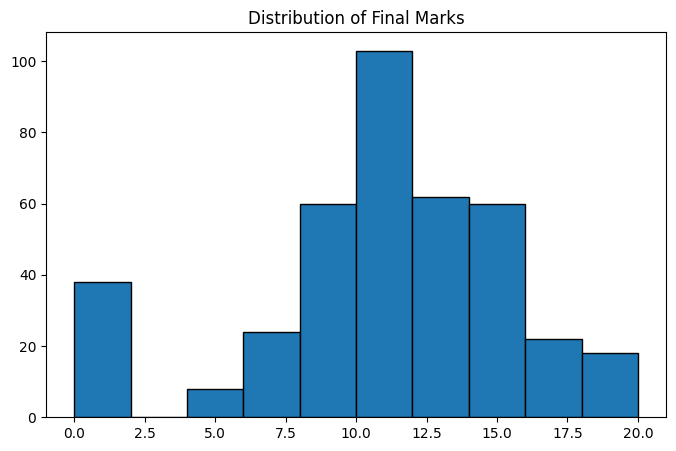

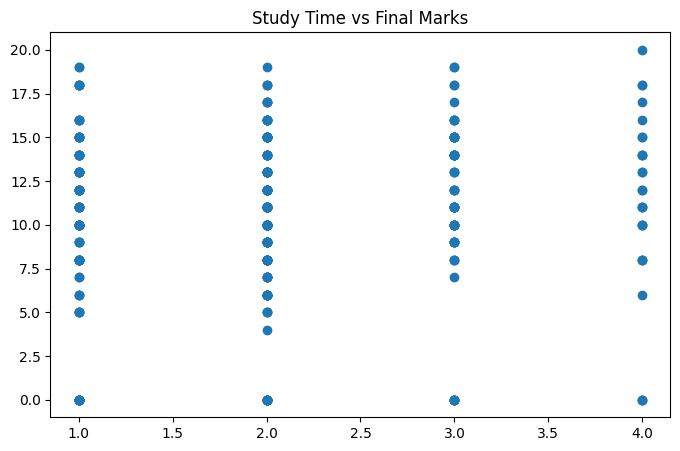

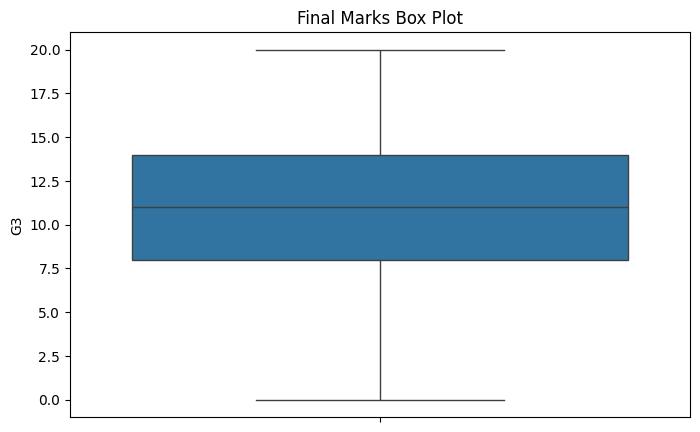

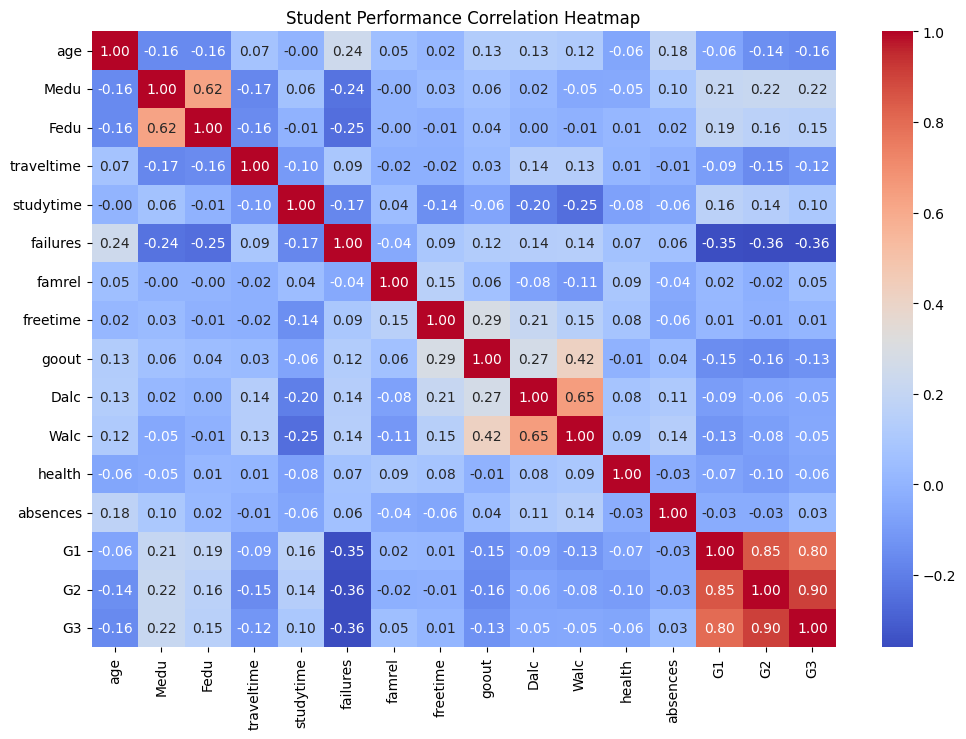

All five visualizations saved successfully!


In [33]:
import os

# Create folder for visualizations
os.makedirs('visualizations', exist_ok=True)

# 1. Bar Chart
plt.figure(figsize=(8, 5))
df_clean[['G1', 'G2', 'G3']].mean().plot(kind='bar')
plt.title('Average Examination Marks')
plt.savefig('visualizations/bar_chart.png')
plt.show()
plt.close()

# 2. Histogram
plt.figure(figsize=(8, 5))
plt.hist(df_clean['G3'], bins=10, edgecolor='black')
plt.title('Distribution of Final Marks')
plt.savefig('visualizations/histogram.png')
plt.show()
plt.close()

# 3. Scatter Plot
plt.figure(figsize=(8, 5))
plt.scatter(df_clean['studytime'], df_clean['G3'])
plt.title('Study Time vs Final Marks')
plt.savefig('visualizations/scatter_plot.png')
plt.show()
plt.close()

# 4. Box Plot
plt.figure(figsize=(8, 5))
sns.boxplot(y=df_clean['G3'])
plt.title('Final Marks Box Plot')
plt.savefig('visualizations/box_plot.png')
plt.show()
plt.close()

# 5. Correlation Heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(df_clean.select_dtypes(include=np.number).corr(),
            annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Student Performance Correlation Heatmap')
plt.savefig('visualizations/heatmap.png')
plt.show()
plt.close()

print("All five visualizations saved successfully!")

In [34]:
import shutil
from google.colab import files

# Compress visualization folder
shutil.make_archive('project_visualizations', 'zip', 'visualizations')

# Download ZIP file
files.download('project_visualizations.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>